# Working with an ONrecorder EMG recording

This notebook walks through a real EMG1 recording saved by ONrecorder (`data/Rec005.csv`): how to read the file, what the header and the two data rows actually contain, and how to deal with the three things that get in the way of analysing it:

1. **Dropped BLE packets**: the samples are not contiguous in time.
2. **Mains interference**: strong 60 Hz and harmonics.
3. **Stimulation artifacts**: large, saturating transients while the IPG is stimulating.

The recording has three parts, separated by gaps where saving was paused:

| Segment | Condition |
|---|---|
| 1 | No stimulation (baseline) |
| 2 | Stimulation on, setting A |
| 3 | Stimulation on, setting B |

Everything below is computed from the CSV, so the same code should work on your own recordings. Change `CSV_PATH` to point at your file.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams.update({"figure.figsize": (11, 3.2), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.3})

CSV_PATH = Path("data/Rec005.csv")

## 1. The file format

An ONrecorder CSV has a short `key,value` header, a line of dashes, then the data. Each BLE packet from the IPG carries **100 samples** and is written as **two lines** that share the same first column:

```
<host timestamp ms>,s0,s1,...,s99          <- raw ADC values
<host timestamp ms>,s0-m,s1-m,...,s99-m    <- same values minus this packet's mean m
```

The timestamp is the Unix time in milliseconds when the PC *received* the packet, not when the IPG sampled it. Sample `i` of a packet is at roughly `timestamp + i / fs`.

In [2]:
def load_onrecorder_csv(path):
    # Returns the header dict, packet timestamps (ms) and two (n_packets, 100) arrays.
    header, rows = {}, []
    with open(path) as f:
        for line in f:
            if line.startswith("---"):
                break
            key, _, value = line.strip().partition(",")
            header[key] = value
        rows = [line.rstrip().split(",") for line in f if line.strip()]

    raw_rows, dc_rows = rows[0::2], rows[1::2]
    assert len(raw_rows) == len(dc_rows), "expected raw/DC-removed line pairs"
    assert all(r[0] == d[0] for r, d in zip(raw_rows, dc_rows)), "timestamps of a pair differ"

    ts_ms = np.array([int(r[0]) for r in raw_rows], dtype=np.int64)
    raw = np.array([r[1:] for r in raw_rows], dtype=float)
    dc_removed = np.array([d[1:] for d in dc_rows], dtype=float)
    return header, ts_ms, raw, dc_removed


header, ts_ms, raw, dc_removed = load_onrecorder_csv(CSV_PATH)
print(f"{raw.shape[0]} packets x {raw.shape[1]} samples = {raw.size:,} samples")
pd.Series(header, name="value").to_frame()

4053 packets x 100 samples = 405,300 samples


,value
Date,2026-07-17
Start Time,16:33:14
Signal Type,EMG1
Sample Rate (raw),6400
Decimation Factor,10
Effective Fs (after DEC),640
FFT size,256
Frequency bin spacing (Hz),2.5
FFT Max Frequency (Hz),320


### What the second row really is

The ONrecorder source (`Form1.cs`, `GET_SENSOR` handler) writes the second line as each sample minus **the mean of its own 100-sample packet**. It is not the high-pass/notch filtered signal you see on screen. The baseline it removes is a staircase, one constant per packet, so wherever the baseline moves, row 2 gets a step at every packet boundary. The start of the recording, while the front end settles, shows this:

Confirmed: row 2 == row 1 minus the per-packet mean


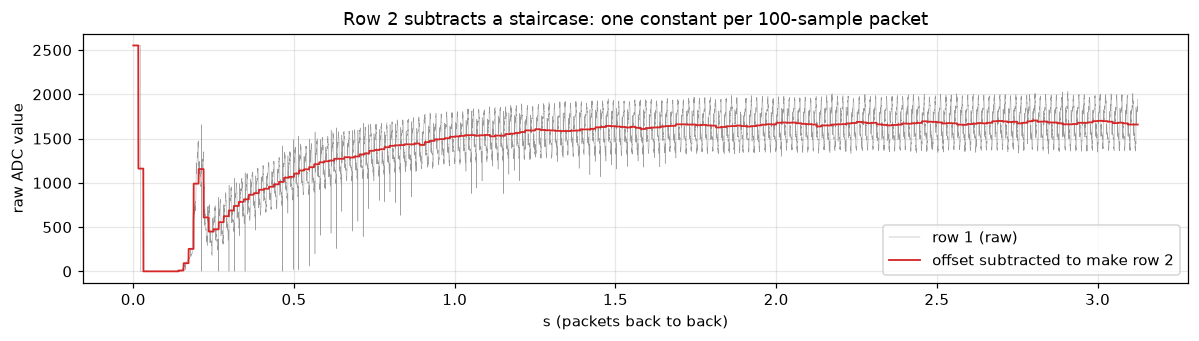

In [3]:
assert np.allclose(dc_removed, raw - raw.mean(axis=1, keepdims=True), atol=1e-5)
print("Confirmed: row 2 == row 1 minus the per-packet mean")

n_pk = 200   # first ~3 s, while the front end settles
t_s = np.arange(n_pk * raw.shape[1]) / 6400
offset = np.repeat(raw[:n_pk].mean(axis=1), raw.shape[1])
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(t_s, raw[:n_pk].ravel(), lw=0.3, color="0.6", label="row 1 (raw)")
ax.plot(t_s, offset, lw=1.2, color="C3", label="offset subtracted to make row 2")
ax.set_xlabel("s (packets back to back)"); ax.set_ylabel("raw ADC value"); ax.legend()
ax.set_title("Row 2 subtracts a staircase: one constant per 100-sample packet")
plt.tight_layout()

Once the signal is steady, the steps nearly vanish: one packet (15.6 ms) is close to one mains cycle (16.7 ms), so every packet has nearly the same mean. They come back whenever the baseline drifts (settling, movement, electrode shifts). For analysis, start from **row 1 (raw)** and apply a proper high-pass filter yourself. The rest of the notebook only uses `raw`.

## 2. Which sampling rate?

The header says `Sample Rate (raw) = 6400`, `Decimation Factor = 10`, `Effective Fs = 640`. The FFT lines are left over from a processing step that is no longer used. Two independent checks show the saved samples are at **6400 Hz, not 640 Hz**:

* **Packet rate.** Packets arrive about every 15–16 ms. 100 samples in 15.6 ms is 6400 Hz; at 640 Hz one packet would take 156 ms.
* **Mains frequency.** The strongest narrow-band peak should land at 60 Hz (US mains). It does only if we assume 6400 Hz.

In [4]:
dt = np.diff(ts_ms)
print(f"median inter-packet interval: {np.median(dt[dt < 1000]):.0f} ms "
      f"(100 samples at 6400 Hz = 15.6 ms; at 640 Hz = 156 ms)")

x_seg2 = raw[600:2000].ravel()
for fs_guess in (640, 2560, 6400):
    f, p = signal.welch(x_seg2 - x_seg2.mean(), fs_guess, nperseg=2**14)
    band = f > 5
    print(f"assume fs = {fs_guess:>4} Hz -> biggest peak at {f[band][np.argmax(p[band])]:7.1f} Hz")

median inter-packet interval: 15 ms (100 samples at 6400 Hz = 15.6 ms; at 640 Hz = 156 ms)
assume fs =  640 Hz -> biggest peak at     6.0 Hz
assume fs = 2560 Hz -> biggest peak at    24.1 Hz
assume fs = 6400 Hz -> biggest peak at    60.2 Hz


In [5]:
FS = 6400.0                    # verified above; don't trust 'Effective Fs' in the header
N_PER_PACKET = raw.shape[1]
PACKET_MS = 1000 * N_PER_PACKET / FS

## 3. Packet timing: gaps and dropped packets

Two kinds of discontinuity show up in the timestamps:

* **Gaps of several seconds**: saving was paused between segments.
* **Missing packets inside a segment**: BLE packets that never reached the PC. The CSV has no packet counter, so the only evidence is that the timestamps advance faster than the samples do.

The PC also receives packets in bursts (intervals of 0–2 ms followed by ~30 ms), so single timestamps jitter by about ±15 ms. Comparing a whole segment's timestamp span with its sample count is more reliable than looking at individual intervals.

,packets,start_s,timestamp_span_s,sample_duration_s,est_missing_pct
segment,,,,,
1,501,0.00,8.76,7.83,10.68
2,1547,13.08,26.26,24.17,7.95
3,2005,43.72,34.25,31.33,8.54


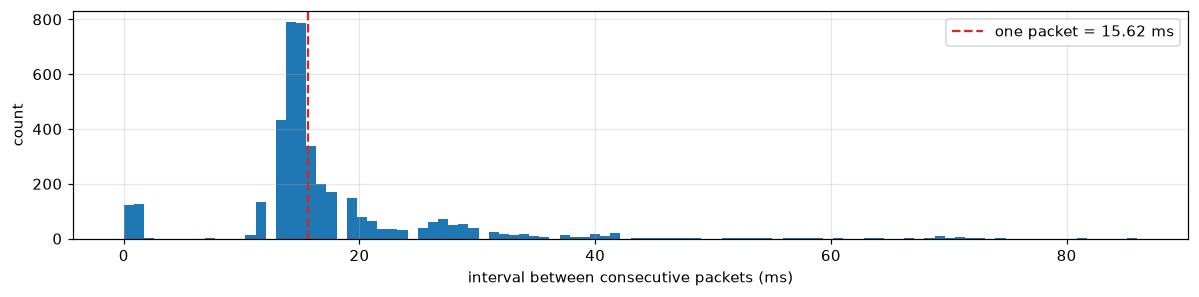

In [6]:
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.hist(dt[dt < 100], bins=100, color="C0")
ax.axvline(PACKET_MS, color="C3", ls="--", label=f"one packet = {PACKET_MS:.2f} ms")
ax.set_xlabel("interval between consecutive packets (ms)"); ax.set_ylabel("count"); ax.legend()
plt.tight_layout()

# Split into segments at pauses longer than 1 s
breaks = np.where(dt > 1000)[0] + 1
bounds = np.r_[0, breaks, len(ts_ms)]
segments = [(a, b) for a, b in zip(bounds[:-1], bounds[1:])]

rows = []
for n, (a, b) in enumerate(segments, 1):
    span_s = (ts_ms[b - 1] - ts_ms[a]) / 1000 + PACKET_MS / 1000
    samples_s = (b - a) * N_PER_PACKET / FS
    rows.append(dict(segment=n, packets=b - a,
                     start_s=(ts_ms[a] - ts_ms[0]) / 1000,
                     timestamp_span_s=span_s, sample_duration_s=samples_s,
                     est_missing_pct=100 * (1 - samples_s / span_s)))
seg_table = pd.DataFrame(rows).set_index("segment")
seg_table.round(2)

Roughly **8–11 % of packets are missing** in every segment. This matters for any analysis that depends on timing:

* If you stitch the packets together back to back and assume `t = n / fs`, events drift earlier and intervals come out too short. Section 6 shows this happening.
* Spectral analysis (PSDs, line noise) is barely affected. A missing packet is a short splice, and the frequency axis depends only on `fs`.

Two practical ways to build a time axis:

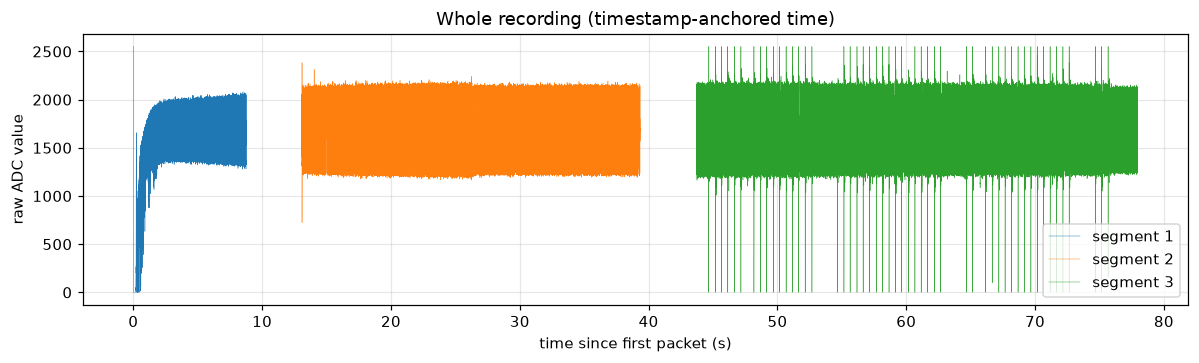

In [7]:
# (a) Contiguous: ignore drops. Fine for spectra and filtering within a segment.
def contiguous(seg):
    a, b = segments[seg]
    return raw[a:b].ravel()

# (b) Timestamp-anchored: each packet starts at its host timestamp. Keeps absolute
#     time across drops (+/- ~15 ms jitter). Use it for event timing.
def anchored_time(seg):
    a, b = segments[seg]
    t = (ts_ms[a:b, None] - ts_ms[0]) / 1000 + np.arange(N_PER_PACKET)[None, :] / FS
    return t.ravel()

fig, ax = plt.subplots(figsize=(11, 3.4))
for s in range(len(segments)):
    ax.plot(anchored_time(s), contiguous(s), lw=0.3, color=f"C{s}", label=f"segment {s + 1}")
ax.set_xlabel("time since first packet (s)"); ax.set_ylabel("raw ADC value")
ax.set_title("Whole recording (timestamp-anchored time)"); ax.legend(loc="lower right")
plt.tight_layout()

**Things to notice**

* **Start-up transient:** at the start of segment 1 the signal sits at 0 and then slowly settles to its operating level, which takes ~2 s. Drop this part before computing baseline statistics.
* **Rails:** the ADC values are bounded at 0 and about 2552. Anything that reaches those values is clipped, so its true amplitude is unknown.
* **The thick band is mostly mains:** most of the ~1000-count spread in every segment is 60 Hz interference, not EMG (see next section).
* **Spikes in segment 3** are stimulation artifacts. Many of them hit both rails.

In [8]:
RAIL_LO, RAIL_HI = 0.0, raw.max()
print(f"rails: {RAIL_LO:.0f} .. {RAIL_HI:.0f}")

SETTLE_S = 2.5
base = contiguous(0)[int(SETTLE_S * FS):]   # baseline with start-up transient removed

rails: 0 .. 2552


## 4. Line noise

Comparing the power spectra of the three segments shows a forest of peaks at 60 Hz and its odd harmonics (180, 300, ... Hz) that dominates everything else.

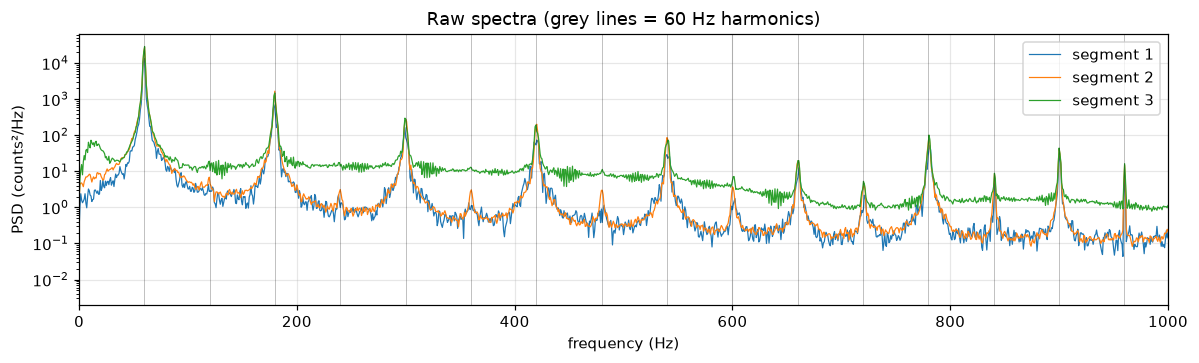

In [9]:
def psd(x, nperseg=2**13):
    return signal.welch(x - np.mean(x), FS, nperseg=nperseg)

fig, ax = plt.subplots(figsize=(11, 3.4))
for s, x in enumerate([base, contiguous(1), contiguous(2)]):
    f, p = psd(x)
    ax.semilogy(f, p, lw=0.8, label=f"segment {s + 1}")
for h in range(60, 1000, 60):
    ax.axvline(h, color="k", lw=0.4, alpha=0.4)
ax.set_xlim(0, 1000); ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("PSD (counts²/Hz)")
ax.set_title("Raw spectra (grey lines = 60 Hz harmonics)"); ax.legend()
plt.tight_layout()

The interference is not a clean sine wave. Zoom into 60 ms of baseline: the signal jumps abruptly every ~8.3 ms (half a mains cycle), alternating up and down. Sharp edges like these are why the harmonics extend so high.

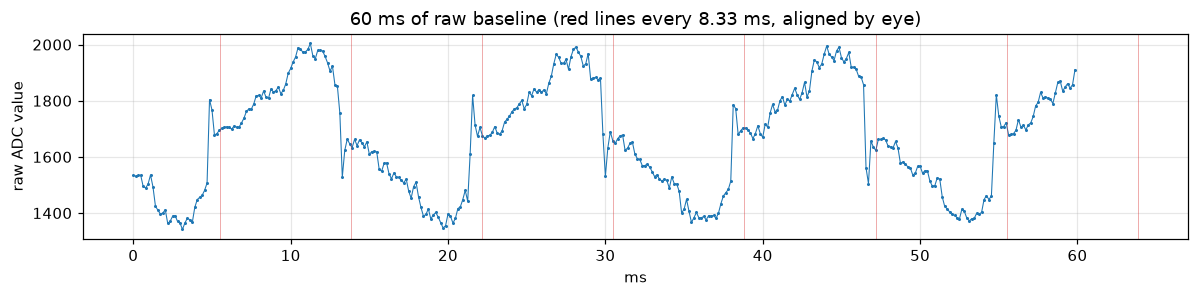

In [10]:
z = base[:int(0.06 * FS)]
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.plot(np.arange(z.size) / FS * 1000, z, ".-", lw=0.7, ms=2)
for c in np.arange(0, 60, 1000 / 120):
    ax.axvline(c + 5.5, color="C3", lw=0.5, alpha=0.5)
ax.set_xlabel("ms"); ax.set_ylabel("raw ADC value")
ax.set_title("60 ms of raw baseline (red lines every 8.33 ms, aligned by eye)")
plt.tight_layout()

A standard cleanup for surface/intramuscular EMG:

1. **Band-pass 20–1000 Hz**: removes slow drift and offset (in place of row 2) and high-frequency noise. Most EMG power is in this band.
2. **Notch at every 60 Hz harmonic** inside the pass band.

All filters are applied forwards and backwards (`sosfiltfilt` / `filtfilt`), so they add **no phase delay**. That matters when you measure latencies.

baseline RMS: raw 203.9 -> cleaned 97.0 counts


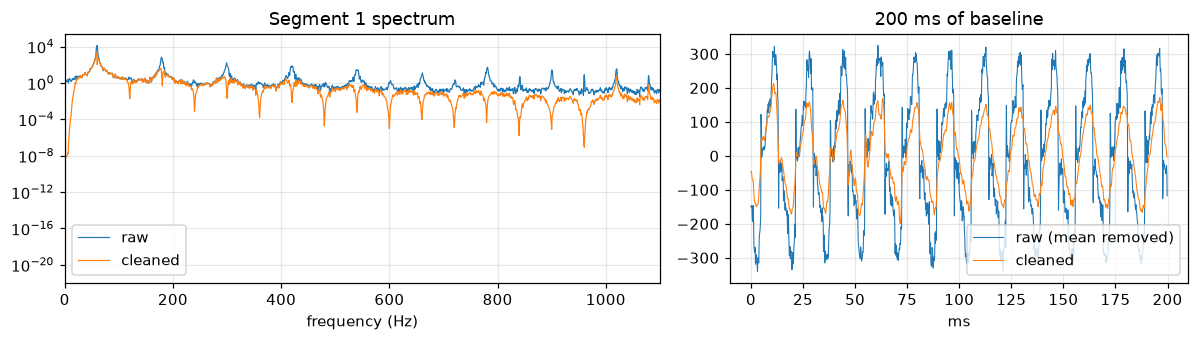

In [11]:
BAND = (20, 1000)
LINE_HZ, NOTCH_Q = 60, 30

_bp = signal.butter(4, BAND, btype="bandpass", fs=FS, output="sos")
_notches = [signal.iirnotch(h, NOTCH_Q, FS) for h in range(LINE_HZ, BAND[1], LINE_HZ)]

def clean(x):
    y = signal.sosfiltfilt(_bp, x - np.mean(x))
    for b, a in _notches:
        y = signal.filtfilt(b, a, y)
    return y

base_clean = clean(base)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1.3, 1]})
f, p0 = psd(base); f, p1 = psd(base_clean)
ax[0].semilogy(f, p0, lw=0.8, label="raw"); ax[0].semilogy(f, p1, lw=0.8, label="cleaned")
ax[0].set_xlim(0, 1100); ax[0].set_xlabel("frequency (Hz)"); ax[0].set_title("Segment 1 spectrum"); ax[0].legend()
t = np.arange(int(0.2 * FS)) / FS * 1000
ax[1].plot(t, base[:t.size] - base.mean(), lw=0.7, label="raw (mean removed)")
ax[1].plot(t, base_clean[:t.size], lw=0.7, label="cleaned")
ax[1].set_xlabel("ms"); ax[1].set_title("200 ms of baseline"); ax[1].legend()
plt.tight_layout()

print(f"baseline RMS: raw {np.std(base):.1f} -> cleaned {np.std(base_clean):.1f} counts")

Notching cuts the baseline RMS roughly in half, but small spikes remain at each mains edge. A notch comb can't fully cancel a waveform with sharp edges. The usual next step is **mains template subtraction**: average many 16.7 ms mains cycles and subtract that template cycle by cycle. That requires a continuous mains phase. Here, every dropped packet shifts the phase by an unknown amount and the host timestamps are too coarse to recover it, so template subtraction isn't attempted in this notebook. A packet counter in the CSV would make it possible (see recommendations).

## 5. Stimulation artifacts: detection

In segment 3 the stimulation artifacts are easy to find because they **saturate the amplifier**: the signal usually hits the upper rail, then the lower rail, and occasionally only one of them. We detect samples at **either** rail and merge hits closer than 50 ms into one event. Outside the start-up transient, segments 1 and 2 never reach the rails, so this detector gives no false positives there.

> ⚠️ Filtering a signal that contains saturating artifacts makes things worse. A notch or band-pass filter turns each artifact into a long ringing tail that can look like a physiological response. **Handle the artifacts before filtering.**

In [12]:
x3 = contiguous(2)
t3 = anchored_time(2)

for s in (0, 1):
    xs = contiguous(s)[int(SETTLE_S * FS):]
    print(f"segment {s + 1} range after settling: {xs.min():.0f} .. {xs.max():.0f}")

hits = np.where((x3 >= RAIL_HI - 2) | (x3 <= RAIL_LO + 2))[0]
onsets = hits[np.r_[True, np.diff(hits) > 0.05 * FS]]
print(f"{onsets.size} saturating artifacts found in segment 3")

ev_t = t3[onsets]                       # timestamp-anchored event times
ev_n = onsets / FS                      # naive 'contiguous' event times

ivl = pd.DataFrame({"timestamp-anchored": np.diff(ev_t), "contiguous (n/fs)": np.diff(ev_n)})
ivl.describe().loc[["count", "50%", "min", "max"]].round(3)

segment 1 range after settling: 1277 .. 2080
segment 2 range after settling: 1165 .. 2242
52 saturating artifacts found in segment 3


,timestamp-anchored,contiguous (n/fs)
count,51.000,51.000
50%,0.502,0.461
min,0.458,0.415
max,2.030,1.828


## 6. Stimulation rate, and why the timestamps matter

Measured on the **contiguous** sample index, the typical inter-artifact interval comes out ~0.46 s. On **timestamp-anchored** time it comes out ~0.50 s. The difference is the dropped packets from Section 3: every missing packet removes 15.6 ms from the contiguous timeline.

Fitting a regular pulse train to the anchored event times gives the stimulation period. The occasional ~1.0–2.5 s intervals are pulses with no rail-hitting artifact. Below we list them and check whether data was received around each one.

In [13]:
k = np.round((ev_t - ev_t[0]) / np.median(np.diff(ev_t))).astype(int)
period, t0 = np.polyfit(k, ev_t, 1)
resid_ms = 1000 * (ev_t - (t0 + period * k))
print(f"stimulation period {period * 1000:.1f} ms  ->  {1 / period:.3f} Hz")
print(f"timing residual (host timestamp jitter): {resid_ms.std():.1f} ms RMS")

expected = t0 + period * np.arange(k.max() + 1)
missing = np.setdiff1d(np.arange(k.max() + 1), k)
rows = []
for m in missing:
    near = np.abs(t3 - expected[m]) < 0.04          # +/- 40 ms, about 3x the jitter
    rows.append(dict(expected_t_s=expected[m], samples_within_40ms=near.sum(),
                     min=x3[near].min(), max=x3[near].max()))
pd.DataFrame(rows).round(2)

stimulation period 500.0 ms  ->  2.000 Hz
timing residual (host timestamp jitter): 12.2 ms RMS


,expected_t_s,samples_within_40ms,min,max
0,47.66,339,1102.0,2201.0
1,53.16,200,1200.0,2146.0
2,53.66,574,1186.0,2193.0
3,54.16,562,1170.0,2172.0
4,63.16,519,1174.0,2297.0
5,63.66,556,1207.0,2183.0
6,64.16,478,1207.0,2259.0
7,65.66,185,1217.0,2170.0
8,73.16,532,1192.0,2170.0
9,73.66,493,1211.0,2176.0


For most of the missing pulses, plenty of samples were received around the expected time, yet the signal stays well inside the rails. The artifact amplitude evidently varies from pulse to pulse, and some pulses produce no visible artifact. A pulse that landed in a dropped packet is also possible: the neighbouring packets' jittery timestamps can hide a 15.6 ms hole. Without a packet counter or a stimulation log, the two can't be told apart.

## 7. Anatomy of one artifact

Zooming in on a single event (raw samples, 6400 Hz = 0.156 ms per sample):

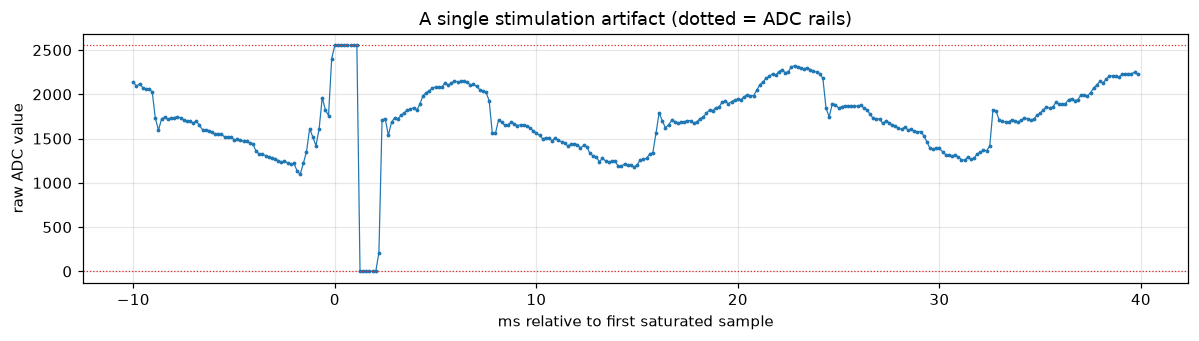

In [14]:
PRE, POST = int(0.010 * FS), int(0.040 * FS)
e = onsets[5]
seg_ms = (np.arange(-PRE, POST)) / FS * 1000
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(seg_ms, x3[e - PRE:e + POST], ".-", lw=0.8, ms=3)
ax.axhline(RAIL_HI, color="C3", ls=":", lw=0.8); ax.axhline(RAIL_LO, color="C3", ls=":", lw=0.8)
ax.set_xlabel("ms relative to first saturated sample"); ax.set_ylabel("raw ADC value")
ax.set_title("A single stimulation artifact (dotted = ADC rails)")
plt.tight_layout()

You can see:

* a few samples pinned at the upper rail, then a few at the lower rail: the pulse drives the front end into saturation for ~1.5–2.5 ms in total;
* a fast recovery, back to the ongoing signal within a fraction of a millisecond;
* before and after the artifact, the step-like mains waveform from Section 4. The jumps at regular ~8.3 ms spacing are mains edges, **not** responses to the stimulus. This is easy to misread.

## 8. Artifact removal: blank and interpolate

The simplest robust method is to **blank** a short window around each artifact, replace it with a straight line between its edges, and only then filter. Because the time spent on the rails varies between pulses, the window here adapts to each event. It starts 2 ms before the first saturated sample, which covers the rising edge visible above, and ends 1 ms after the last saturated sample within 10 ms of it.

Other common approaches, roughly from simplest to most involved: template subtraction (average the artifact and subtract it), adaptive filtering, and hardware-side blanking. Template subtraction doesn't work well here because the artifact saturates, so its true shape is lost, and because timestamp jitter makes alignment by timestamp unreliable. Aligning on the detected onset, as we do, avoids the second problem.

blanked window ends 1.4-4.1 ms after onset


mean |difference| outside the blanked window, within +/-50 ms: 21 counts (peak 227); cleaned baseline RMS is 97


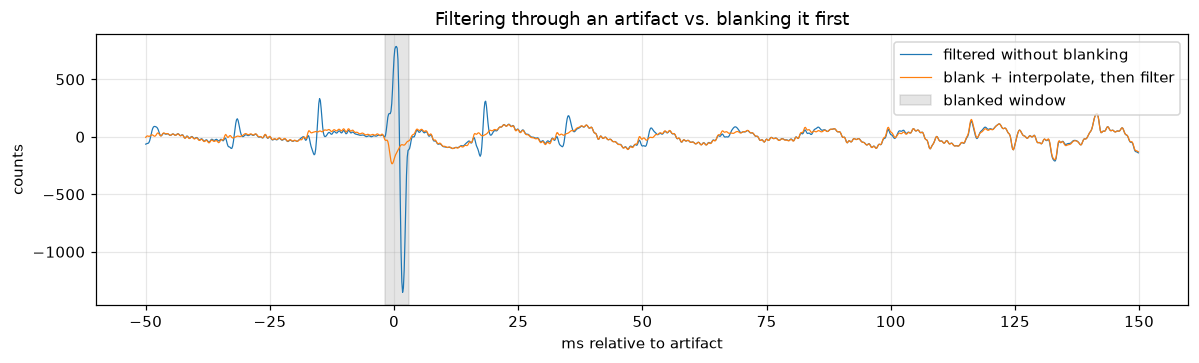

In [15]:
PRE_MARGIN, POST_MARGIN, SEARCH = 0.002, 0.001, 0.010   # seconds

def artifact_windows(x, onsets):
    # (start, stop) sample indices of each artifact: first to last rail sample, plus a margin
    out = []
    for e in onsets:
        seg = x[e:e + int(SEARCH * FS)]
        last = e + np.where((seg >= RAIL_HI - 2) | (seg <= RAIL_LO + 2))[0].max()
        out.append((max(e - int(PRE_MARGIN * FS), 0), min(last + int(POST_MARGIN * FS), len(x) - 1)))
    return out

def blank_and_interpolate(x, windows):
    y = x.astype(float).copy()
    for i0, i1 in windows:
        y[i0:i1 + 1] = np.linspace(y[i0], y[i1], i1 - i0 + 1)
    return y

windows = artifact_windows(x3, onsets)
blank_ms = np.array([(i1 - e) / FS * 1000 for (i0, i1), e in zip(windows, onsets)])
print(f"blanked window ends {blank_ms.min():.1f}-{blank_ms.max():.1f} ms after onset")
BLANK = (-PRE_MARGIN, blank_ms.max() / 1000)   # widest window, for shading plots

x3_blanked = blank_and_interpolate(x3, windows)
naive = clean(x3)              # filter straight through the artifacts
proper = clean(x3_blanked)     # blank first, then filter

e = onsets[5]
w = slice(e - int(0.05 * FS), e + int(0.15 * FS))
tt = (np.arange(w.start, w.stop) - e) / FS * 1000
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(tt, naive[w], lw=0.8, label="filtered without blanking")
ax.plot(tt, proper[w], lw=0.8, label="blank + interpolate, then filter")
ax.axvspan((windows[5][0] - e) / FS * 1000, (windows[5][1] - e) / FS * 1000, color="k", alpha=0.1, label="blanked window")
ax.set_xlabel("ms relative to artifact"); ax.set_ylabel("counts"); ax.legend(loc="upper right")
ax.set_title("Filtering through an artifact vs. blanking it first")
plt.tight_layout()

# How far does the filter smear each artifact? Compare the two versions outside the blanked windows.
diff = np.abs(naive - proper)
lags = np.arange(-int(0.05 * FS), int(0.05 * FS))
smear = np.mean([diff[e + lags] for e in onsets[1:-1]], axis=0)
outside = (lags / FS < BLANK[0]) | (lags / FS > BLANK[1])
print(f"mean |difference| outside the blanked window, within +/-50 ms: {smear[outside].mean():.0f} counts "
      f"(peak {smear[outside].max():.0f}); cleaned baseline RMS is {np.std(base_clean):.0f}")

## 9. Stimulus-triggered averaging

Cutting an epoch around every artifact and averaging them shows what is consistently time-locked to the stimulus. Uncorrelated noise averages away. We use the **raw** signal with only the slow offset removed (no notch), so no filter can smear the artifact into the response.

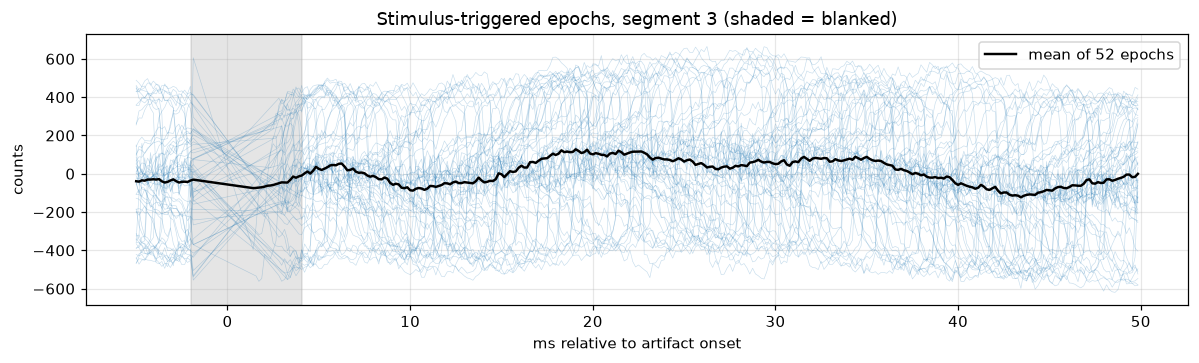

In [16]:
PRE, POST = int(0.005 * FS), int(0.050 * FS)
hp = signal.butter(2, 10, btype="highpass", fs=FS, output="sos")
x3_hp = signal.sosfiltfilt(hp, x3_blanked)       # blanked, offset removed
ok = onsets[(onsets > PRE) & (onsets < len(x3) - POST)]
epochs = np.stack([x3_hp[e - PRE:e + POST] for e in ok])
ep_ms = np.arange(-PRE, POST) / FS * 1000

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(ep_ms, epochs.T, color="C0", lw=0.4, alpha=0.25)
ax.plot(ep_ms, epochs.mean(0), color="k", lw=1.6, label=f"mean of {len(ok)} epochs")
ax.axvspan(BLANK[0] * 1000, BLANK[1] * 1000, color="k", alpha=0.1)
ax.set_xlabel("ms relative to artifact onset"); ax.set_ylabel("counts"); ax.legend()
ax.set_title("Stimulus-triggered epochs, segment 3 (shaded = blanked)")
plt.tight_layout()

The individual epochs are dominated by the step-like mains waveform. The stimulus isn't locked to the mains phase, so it averages out, and the mean shows **no large, consistent response outside the blanked window**. Any short-latency evoked response would overlap the 1.5–2.5 ms during which the amplifier is saturated, so this recording can't show it. Reducing saturation would make this measurable: lower front-end gain, more electrode separation from the stimulation site, or hardware blanking during the pulse.

What the data *does* show reliably is how hard each pulse drives the front end. The time spent on the rails per pulse is a simple artifact-severity metric to track:

total time saturated per pulse: median 1.88 ms


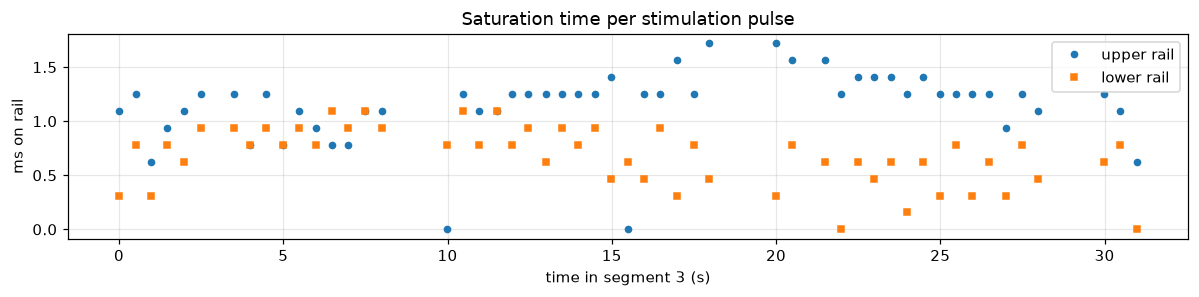

In [17]:
n_hi = np.array([np.sum(x3[i0:i1 + 1] >= RAIL_HI - 2) for i0, i1 in windows])
n_lo = np.array([np.sum(x3[i0:i1 + 1] <= RAIL_LO + 2) for i0, i1 in windows])

fig, ax = plt.subplots(figsize=(11, 2.8))
tt_ev = t3[onsets] - t3[onsets][0]
ax.plot(tt_ev, n_hi / FS * 1000, "o", ms=4, label="upper rail")
ax.plot(tt_ev, n_lo / FS * 1000, "s", ms=4, label="lower rail")
ax.set_xlabel("time in segment 3 (s)"); ax.set_ylabel("ms on rail"); ax.legend()
ax.set_title("Saturation time per stimulation pulse")
plt.tight_layout()
print(f"total time saturated per pulse: median {np.median(n_hi + n_lo) / FS * 1000:.2f} ms")

## 10. Segment 2: artifacts below the rails

Segment 2 has stimulation on but **no saturating artifacts**, so the rail detector finds nothing. A smaller artifact would have to be found another way, for example by folding the signal at the stimulation period. With ±12 ms of host-timestamp jitter and missing packets, though, the fold smears a sub-millisecond artifact across many bins. A quick check on this file doesn't separate segment 2 from the baseline.

Here are the high-frequency envelopes of the three segments side by side:

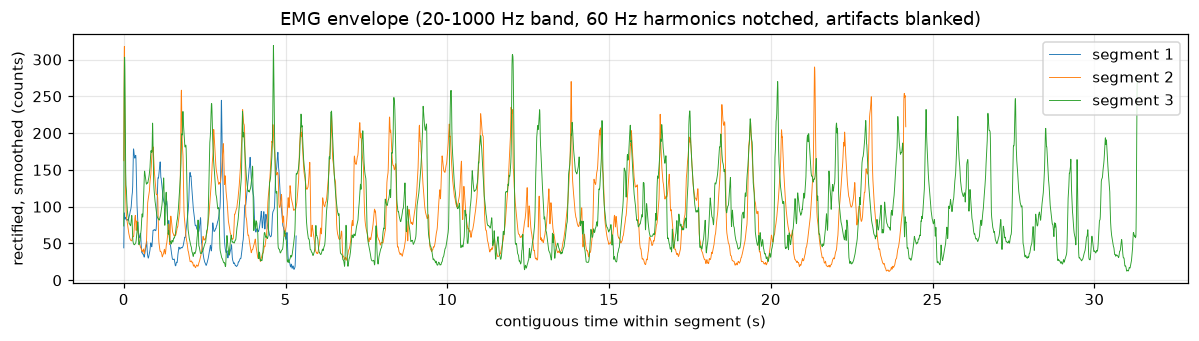

In [18]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for s, x in enumerate([base, contiguous(1), x3_blanked]):
    y = np.abs(clean(x))
    env = signal.sosfiltfilt(signal.butter(2, 20, fs=FS, output="sos"), y)
    ax.plot(np.arange(env.size) / FS, env, lw=0.6, label=f"segment {s + 1}")
ax.set_xlabel("contiguous time within segment (s)"); ax.set_ylabel("rectified, smoothed (counts)")
ax.set_title("EMG envelope (20-1000 Hz band, 60 Hz harmonics notched, artifacts blanked)"); ax.legend()
plt.tight_layout()

Reliably handling artifacts that stay inside the rails needs the stimulation timing to be recorded, not inferred. See the recommendations below.

## 11. Summary

**Reading the file**
* Use row 1 (raw). Row 2 is the per-packet mean removed, which adds 64 Hz steps.
* The samples are at **6400 Hz**. Ignore `Decimation Factor`, `Effective Fs` and the FFT lines in the header.
* Each segment is missing ~8–11 % of packets. Use timestamp-anchored time for anything about timing.

**Cleaning**
* Detect stimulation artifacts on **both** rails and blank them **first**, then band-pass (20–1000 Hz) and notch every 60 Hz harmonic.
* The mains interference has sharp edges every 8.3 ms. Don't mistake them for responses, and expect small residual spikes after notching.
* In this recording the amplifier saturates for ~2 ms per pulse, which hides any short-latency response.
* Trim the ~2 s start-up transient at the beginning of a recording.

**Possible ONrecorder improvements** (suggestions from working with this file)
1. Write the packet counter (`bResponse[3]`, already parsed as `CurPacket`) to the CSV, so dropped packets can be found exactly instead of estimated. That would also make mains template subtraction possible.
2. Fix the header: drop the FFT lines and write the rate the saved samples are actually at.
3. Rename the second row (e.g. `packet-mean removed`) or replace it with the filtered stream shown in the plot.
4. Log stimulation on/off commands and their parameters to the CSV with timestamps. Then artifacts can be located even when they don't saturate.
5. `Getting-Started.md` lists the EMG sampling rate as 2560 Hz, but the EMG1 mode in `Form1.cs` and this recording are at 6400 Hz.